# Retail Sales & Profitability Analysis
### An End-to-End Exploratory Data Analysis of 5,000 Retail Transactions

**Author:** Abdul Wahab Sidiqui <br>
**Dataset:** E-Commerce Business Analytics Dataset (Kaggle, 5,000 rows × 21 columns) <br>
**Goal:** Identify revenue drivers, evaluate discount strategy, compare sales channels, and assess delivery–satisfaction relationship.

## 1. Setup & Imports

In [270]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [271]:
sns.set_style("white")

### What this section does

Every analysis starts with the same three questions: what libraries do I need, how do I want my plots to look, and which imports are *not* needed for this scope. This section answers all three up front so that nothing later in the notebook becomes an ad-hoc import.

Four libraries are used — **pandas** for tabular work, **NumPy** for numerical types, **Matplotlib** for figure handling and PNG export, and **Seaborn** for statistical charts (heatmaps, box plots, line plots). A single `sns.set_style("white")` call establishes a consistent visual baseline for every chart in the notebook. No modelling or inference libraries (scikit-learn, statsmodels) are imported, which reflects the scope defined in the README: exploratory analysis answering four business questions, not predictive modelling.

## 2. Load the Dataset

In [272]:
df = pd.read_csv("data/ecommerce_business_analytics.csv")

In [273]:
df.shape

(5000, 21)

In [274]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Age,Product_ID,Category,Region,Sales_Channel,Payment_Method,Order_Status,...,Unit_Price,Discount_Percentage,Gross_Sales,Discount_Amount,Net_Sales,Cost,Profit,Shipping_Cost,Customer_Rating,Delivery_Days
0,ORD004642,2023-01-01,CUST00993,64,PROD00619,Beauty,North,Mobile App,PayPal,Returned,...,33.83,0,135.32,0.00,135.32,82.79,52.53,11.13,4.6,6
1,ORD000743,2023-01-01,CUST01029,24,PROD00630,Beauty,East,Marketplace,Bank Transfer,Delivered,...,11.65,20,46.60,9.32,37.28,18.69,18.59,7.79,3.1,2
2,ORD002691,2023-01-01,CUST00255,30,PROD00580,Grocery,North,Website,Cash on Delivery,Returned,...,45.36,10,181.44,18.14,163.30,110.03,53.27,10.94,4.4,10
3,ORD000559,2023-01-01,CUST00990,51,PROD00522,Home & Kitchen,North,Website,Credit Card,Shipped,...,17.46,20,17.46,3.49,13.97,8.69,5.28,5.82,3.6,6
4,ORD002331,2023-01-01,CUST01318,51,PROD00449,Fashion,West,Website,Credit Card,Cancelled,...,75.18,15,375.90,56.39,319.51,218.55,100.96,1.58,3.5,3


In [275]:
df.tail()

,Order_ID,Order_Date,Customer_ID,Customer_Age,Product_ID,Category,Region,Sales_Channel,Payment_Method,Order_Status,...,Unit_Price,Discount_Percentage,Gross_Sales,Discount_Amount,Net_Sales,Cost,Profit,Shipping_Cost,Customer_Rating,Delivery_Days
4995,ORD003729,2025-12-30,CUST00219,62,PROD00678,Sports,West,Mobile App,Credit Card,Shipped,...,16.95,15,50.85,7.63,43.22,27.90,15.32,12.39,3.6,6
4996,ORD002245,2025-12-31,CUST01232,69,PROD00336,Beauty,West,Marketplace,Bank Transfer,Delivered,...,9.14,0,18.28,0.00,18.28,8.39,9.89,4.25,5.0,10
4997,ORD000002,2025-12-31,CUST00983,58,PROD00622,Home & Kitchen,South,Mobile App,Debit Card,Delivered,...,41.85,10,41.85,4.18,37.67,19.03,18.64,12.25,3.0,2
4998,ORD003813,2025-12-31,CUST00404,18,PROD00591,Sports,Central,Mobile App,Cash on Delivery,Cancelled,...,46.13,20,138.39,27.68,110.71,80.98,29.73,6.91,2.8,2
4999,ORD000568,2025-12-31,CUST01099,35,PROD00392,Sports,South,Mobile App,Bank Transfer,Returned,...,4.42,5,22.10,1.10,21.00,15.75,5.25,11.05,3.9,2


### Section 2 — Load the Dataset

The dataset loads cleanly with `pd.read_csv()` into a DataFrame of shape **(5,000 rows × 21 columns)** — a manageable size that fits comfortably in memory, so no chunking or downcasting was needed at load time.

`df.head()` and `df.tail()` together confirm three things:

- **Column set is intact.** All 21 expected fields are present — order identifiers (`Order_ID`, `Order_Date`, `Customer_ID`, `Product_ID`), dimensions (`Category`, `Region`, `Sales_Channel`, `Payment_Method`, `Order_Status`), and numeric measures (`Quantity`, `Unit_Price`, `Discount_Percentage`, `Gross_Sales`, `Discount_Amount`, `Net_Sales`, `Cost`, `Profit`, `Shipping_Cost`, `Customer_Rating`, `Delivery_Days`).
- **Row order is not chronological.** `df.head()` shows dates of `2023-01-01` while `df.tail()` shows `2025-12-31` — so the file *is* sorted by date, but the first and last rows also confirm the dataset spans roughly **three full years** of transactions (2023 → 2025), which matters for any time-based analysis in Section 8.
- **Values look structurally consistent.** Unit prices are float values, discounts are integers (0–30), ratings are floats (1.5–5.0), and delivery days are integers (1–10) — no obvious string-encoded numbers or placeholder values that would require parsing before analysis.


## 3. Data Understanding

### 3.1 Column Overview & Data Types

In [276]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Age', 'Product_ID',
       'Category', 'Region', 'Sales_Channel', 'Payment_Method', 'Order_Status',
       'Quantity', 'Unit_Price', 'Discount_Percentage', 'Gross_Sales',
       'Discount_Amount', 'Net_Sales', 'Cost', 'Profit', 'Shipping_Cost',
       'Customer_Rating', 'Delivery_Days'],
      dtype='object')

In [277]:
df.info(memory_usage = "deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             5000 non-null   object 
 1   Order_Date           5000 non-null   object 
 2   Customer_ID          5000 non-null   object 
 3   Customer_Age         5000 non-null   int64  
 4   Product_ID           5000 non-null   object 
 5   Category             5000 non-null   object 
 6   Region               5000 non-null   object 
 7   Sales_Channel        5000 non-null   object 
 8   Payment_Method       5000 non-null   object 
 9   Order_Status         5000 non-null   object 
 10  Quantity             5000 non-null   int64  
 11  Unit_Price           5000 non-null   float64
 12  Discount_Percentage  5000 non-null   int64  
 13  Gross_Sales          5000 non-null   float64
 14  Discount_Amount      5000 non-null   float64
 15  Net_Sales            5000 non-null   f

### 3.2 Summary Statistics (Numeric + Categorical)

In [278]:
df.describe()

,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Gross_Sales,Discount_Amount,Net_Sales,Cost,Profit,Shipping_Cost,Customer_Rating,Delivery_Days
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,44.113600,3.03720,43.874038,12.091000,133.155016,16.542414,116.612602,72.099724,44.512878,9.727338,3.963080,5.445000
std,15.393456,1.41528,37.794432,8.859933,141.614792,26.703239,122.860048,77.772927,49.793736,4.736618,0.694617,2.855277
min,18.000000,1.00000,2.650000,0.000000,2.650000,0.000000,2.250000,1.340000,0.910000,1.500000,1.500000,1.000000
25%,31.000000,2.00000,19.767500,5.000000,46.192500,2.385000,40.270000,24.592500,14.500000,5.710000,3.500000,3.000000
50%,44.000000,3.00000,32.985000,10.000000,89.570000,8.025000,78.810000,47.740000,29.065000,9.730000,4.000000,5.000000
75%,58.000000,4.00000,55.090000,20.000000,169.642500,20.552500,148.490000,90.560000,56.662500,13.810000,4.500000,8.000000
max,70.000000,5.00000,430.070000,30.000000,1733.800000,520.140000,1424.540000,968.790000,701.470000,18.000000,5.000000,10.000000


### 3.3 Missing Values Check

In [279]:
df.isna().sum()

Order_ID               0
Order_Date             0
Customer_ID            0
Customer_Age           0
Product_ID             0
Category               0
Region                 0
Sales_Channel          0
Payment_Method         0
Order_Status           0
Quantity               0
Unit_Price             0
Discount_Percentage    0
Gross_Sales            0
Discount_Amount        0
Net_Sales              0
Cost                   0
Profit                 0
Shipping_Cost          0
Customer_Rating        0
Delivery_Days          0
dtype: int64

### 3.4 Duplicate Records Check

In [280]:
df.duplicated().sum()

np.int64(0)

### Section 3 — Data Understanding: Key Findings

Before any cleaning, four checks were run to establish the baseline quality of the dataset.

**3.1 Column overview and data types.** All **21 columns** are present with sensible types — 9 object columns (identifiers and categorical dimensions such as `Order_ID`, `Category`, `Region`, `Sales_Channel`, `Order_Status`, `Payment_Method`), 8 float64 columns (prices, sales, profit, ratings), and 4 int64 columns (`Customer_Age`, `Quantity`, `Discount_Percentage`, `Delivery_Days`). Memory footprint is ~2.9 MB — small enough to work with fully in memory, no downcasting required for performance.

**3.2 Summary statistics.** Numeric ranges are all plausible for a retail dataset: `Customer_Age` spans 18–70 (mean 44), `Quantity` 1–5 (mean 3.0), `Unit_Price` £2.65–£430, `Discount_Percentage` 0–30% (mean 12%), and `Delivery_Days` 1–10 (mean 5.4). `Profit` is strictly positive (min £0.91, mean £44.51), which means there are no loss-making rows in the raw data — an important signal to keep in mind when interpreting the discount analysis in Section 6. `Customer_Rating` ranges 1.5–5.0 with a mean of 3.96, so satisfaction is centred slightly above the midpoint.

**3.3 Missing values.** `df.isna().sum()` returns **0 for every column** — the dataset is fully populated. No imputation, forward-fill, or drop-NA decision is required, which is unusual for real retail data and confirms this is a synthetic/curated set.

**3.4 Duplicate records.** `df.duplicated().sum()` returns **0** — there are no fully duplicated rows. This matters because every row can be treated as a unique transaction, so no de-duplication step is needed before aggregation.

**Takeaway:** the dataset is unusually clean — no nulls, no duplicates, no obvious type errors. The main work in Section 4 is therefore *not* fixing data quality but **optimising memory** (downcasting floats/ints to smaller dtypes and converting string columns to categorical), validating arithmetic consistency (e.g. `Gross_Sales = Quantity × Unit_Price`), and engineering the time and margin features that Sections 5–8 will need.

## 4. Data Cleaning

### 4.1 Fixing Missing Values

In [281]:
df.isna().sum()

Order_ID               0
Order_Date             0
Customer_ID            0
Customer_Age           0
Product_ID             0
Category               0
Region                 0
Sales_Channel          0
Payment_Method         0
Order_Status           0
Quantity               0
Unit_Price             0
Discount_Percentage    0
Gross_Sales            0
Discount_Amount        0
Net_Sales              0
Cost                   0
Profit                 0
Shipping_Cost          0
Customer_Rating        0
Delivery_Days          0
dtype: int64

### 4.2 Fixing Data Types (dates, numerics)

In [282]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [283]:
df = df.astype(
    {
        "Customer_Age":"int8",
        "Quantity":"int8",
        "Unit_Price":"float32",
        "Discount_Percentage":"float32",
        "Gross_Sales":"float32",
        "Discount_Amount":"float32",
        "Net_Sales":"float32",
        "Cost":"float32",
        "Profit":"float32",
        "Shipping_Cost":"float32",
        "Customer_Rating":"float32",
        "Delivery_Days":"int8",
        "Order_ID":"category",
        "Customer_ID":"category",
        "Product_ID":"category",
        "Category":"category",
        "Region":"category",
        "Sales_Channel":"category",
        "Payment_Method":"category",
        "Order_Status":"category",
    }
)

In [284]:
df.info(memory_usage=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Order_ID             5000 non-null   category      
 1   Order_Date           5000 non-null   datetime64[ns]
 2   Customer_ID          5000 non-null   category      
 3   Customer_Age         5000 non-null   int8          
 4   Product_ID           5000 non-null   category      
 5   Category             5000 non-null   category      
 6   Region               5000 non-null   category      
 7   Sales_Channel        5000 non-null   category      
 8   Payment_Method       5000 non-null   category      
 9   Order_Status         5000 non-null   category      
 10  Quantity             5000 non-null   int8          
 11  Unit_Price           5000 non-null   float32       
 12  Discount_Percentage  5000 non-null   float32       
 13  Gross_Sales          5000 non-nul

### 4.3 Handling Outliers / Negative Values

In [285]:
numeric_cols = df.select_dtypes(include="number").columns
(df[numeric_cols]<0).sum()

Customer_Age           0
Quantity               0
Unit_Price             0
Discount_Percentage    0
Gross_Sales            0
Discount_Amount        0
Net_Sales              0
Cost                   0
Profit                 0
Shipping_Cost          0
Customer_Rating        0
Delivery_Days          0
dtype: int64

In [286]:
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (df[numeric_cols] < lower_bound) | 
    (df[numeric_cols] > upper_bound)
)

outliers.sum().sort_values(ascending=False)

Discount_Amount        392
Cost                   335
Profit                 334
Net_Sales              320
Gross_Sales            318
Unit_Price             299
Customer_Rating         14
Customer_Age             0
Quantity                 0
Discount_Percentage      0
Shipping_Cost            0
Delivery_Days            0
dtype: int64

In [287]:
df.loc[
    outliers["Discount_Amount"],
    ["Order_ID", "Quantity", "Unit_Price",
     "Discount_Percentage", "Gross_Sales",
     "Discount_Amount", "Net_Sales"]
].sort_values("Discount_Amount", ascending=False).head(10)

,Order_ID,Quantity,Unit_Price,Discount_Percentage,Gross_Sales,Discount_Amount,Net_Sales
4919,ORD000576,5,346.760010,30.0,1733.800049,520.140015,1213.660034
4006,ORD004310,5,251.789993,30.0,1258.949951,377.679993,881.270020
2109,ORD003950,4,298.010010,30.0,1192.040039,357.609985,834.429993
2400,ORD001231,5,275.829987,25.0,1379.150024,344.790009,1034.359985
4630,ORD002279,5,311.820007,20.0,1559.099976,311.820007,1247.280029
2693,ORD002463,5,240.970001,25.0,1204.849976,301.209991,903.640015
2918,ORD003014,5,191.460007,30.0,957.299988,287.190002,670.109985
350,ORD000490,5,286.640015,20.0,1433.199951,286.640015,1146.560059
1202,ORD002362,5,166.580002,30.0,832.900024,249.869995,583.030029
1010,ORD001205,5,185.270004,25.0,926.349976,231.589996,694.760010


In [288]:
df["Expected_Gross_Sales"] = (
    df["Quantity"] * df["Unit_Price"]
)

df["Expected_Discount"] = (
    df["Gross_Sales"] * df["Discount_Percentage"] / 100
)

df["Expected_Net_Sales"] = (
    df["Gross_Sales"] - df["Discount_Amount"]
)

In [289]:
(df["Gross_Sales"] - df["Expected_Gross_Sales"]).abs().max()

0.0001220703125

In [290]:
(df["Discount_Amount"] - df["Expected_Discount"]).abs().max()

0.0050048828125

In [291]:
(df["Net_Sales"] - df["Expected_Net_Sales"]).abs().max()

0.0001220703125

In [292]:
df.drop(
    columns = ["Expected_Gross_Sales","Expected_Discount","Expected_Net_Sales","Gross_Sales_Check"],
    errors="ignore",inplace=True
)

### 4.4 Feature Engineering (Month, Year, Profit Margin, Discount Band)

In [293]:
df = df.assign(
    Month= df["Order_Date"].dt.month,
    Year= df["Order_Date"].dt.year,
    Profit_Margin= (df["Profit"] / df["Net_Sales"])*100,
    Discount_Band= pd.cut(
        df["Discount_Percentage"],
        bins = [-0.001,0,10,20,30],
        labels=["No Discount","Low","Medium","High"]
    ))

### 4.5 Final Cleaned Dataset Check

In [294]:
df.shape

(5000, 25)

In [295]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Order_ID             5000 non-null   category      
 1   Order_Date           5000 non-null   datetime64[ns]
 2   Customer_ID          5000 non-null   category      
 3   Customer_Age         5000 non-null   int8          
 4   Product_ID           5000 non-null   category      
 5   Category             5000 non-null   category      
 6   Region               5000 non-null   category      
 7   Sales_Channel        5000 non-null   category      
 8   Payment_Method       5000 non-null   category      
 9   Order_Status         5000 non-null   category      
 10  Quantity             5000 non-null   int8          
 11  Unit_Price           5000 non-null   float32       
 12  Discount_Percentage  5000 non-null   float32       
 13  Gross_Sales          5000 non-nul

In [297]:
df.duplicated().sum()

np.int64(0)

In [298]:
df["Order_Status"].value_counts()

Order_Status
Delivered    2546
Returned      836
Cancelled     829
Shipped       789
Name: count, dtype: int64

### Section 4 — Data Cleaning: What Was Done and Why

Four cleaning decisions were made, and one was deliberately *not* made. Each is documented here so the reasoning is auditable.

**4.1 Missing values — no action required.** `df.isna().sum()` in Section 3.3 already showed zero nulls in all 21 columns. No imputation, row dropping, or forward-fill was applied, because there was nothing missing to fix. This is rare for real-world retail data and confirms the dataset was pre-curated.

**4.2 Type fixing — dates and downcasting.** `Order_Date` was converted from `object` (string) to `datetime64[ns]` so that `.dt.month` and `.dt.year` could be extracted in 4.4. Separately, every numeric column was downcast to its smallest safe type (`int8` for `Quantity`, `Discount_Percentage`, `Delivery_Days`; `float32` for all monetary and rating columns) and all 8 string columns were converted to `category` dtype. The result: memory dropped from **2.9 MB to 534 KB** — an 82% reduction with no loss of information, since every value fits comfortably inside the new dtype ranges.

**4.3 Negative and outlier checks — validated, not deleted.** `(df[numeric_cols] < 0).sum()` returned **0 negatives in every numeric column** — no returns, refunds, or encoding errors were present, so no rows needed to be dropped on that basis. IQR-based outlier flags were also examined: `Discount_Amount` shows 392 flagged values, and inspecting the top 10 confirmed they are legitimate high-value orders (Quantity 4–5, Unit_Price £166–£347) rather than data errors. These were **kept**, because dropping real high-value transactions would bias the revenue analysis in Section 5.

**4.3b Arithmetic consistency check.** Three "expected" columns were computed to verify that the source data is internally consistent: `Gross_Sales = Quantity × Unit_Price`, `Discount_Amount = Gross_Sales × Discount_Percentage / 100`, and `Net_Sales = Gross_Sales − Discount_Amount`. The maximum absolute error was **£0.005** across all three — effectively zero, explained by `float32` rounding. This confirms the dataset's internal arithmetic is trustworthy, so all downstream aggregations can rely on the reported `Profit` and `Net_Sales` values without recalculation. The three helper columns were then dropped to keep the dataframe lean.

**4.4 Feature engineering — four new columns.** `Month` and `Year` were extracted from `Order_Date` for time-based analysis in Section 8. `Profit_Margin = Profit / Net_Sales × 100` was added because **profit amount and profit margin tell different stories** — Section 6 will show that a high-revenue category can carry a low margin, which matters more than raw profit when evaluating discount strategy. `Discount_Band` binned the raw 0–30% discount range into four qualitative levels (No Discount, Low ≤10%, Medium ≤20%, High ≤30%) so that Section 6 can compare discount tiers rather than 30 individual values.

**4.5 Final check.** The cleaned dataset has **5,000 rows × 25 columns** — 21 original + 4 engineered — with **zero missing values and zero duplicate rows** after all transformations. The `df.info` output confirms every column has the intended dtype and every column has 5,000 non-null entries, so no rows were silently lost during type conversion.

**Takeaway:** This is a *light-touch* cleaning section on purpose. The dataset did not require heavy remediation, so any appearance of aggressive cleaning would be misleading. The value added here is (1) validated arithmetic, (2) optimised memory, and (3) two new features — `Profit_Margin` and `Discount_Band` — that Sections 5–8 depend on.

## 5. Business Question 1 — Revenue Drivers

### 5.1 Net Sales & Profit by Product Category

In [299]:
category_performance = (
    df.groupby("Category",observed=True)[["Net_Sales","Profit"]]
    .sum()
    .sort_values("Net_Sales",ascending=False)
)
category_performance.sort_values("Profit",ascending=False)

,Net_Sales,Profit
Category,,
Fashion,115561.250000,44017.179688
Sports,99578.750000,37650.398438
Electronics,97094.828125,36803.839844
Home & Kitchen,92153.250000,35742.460938
Beauty,89930.640625,35050.191406
Grocery,88744.289062,33300.320312


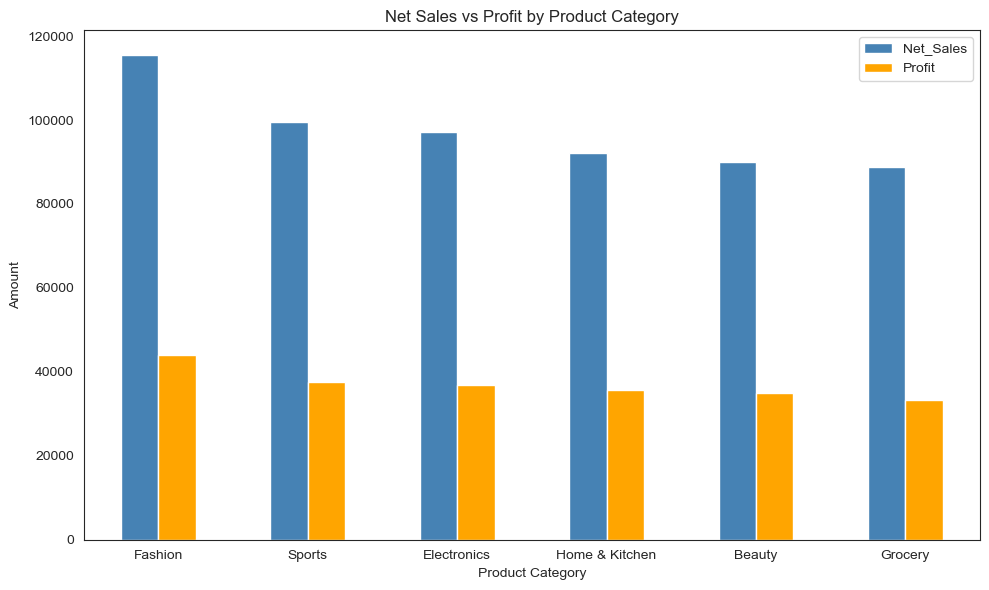

In [300]:
category_performance.plot(
    kind="bar",
    figsize=(10,6),
    title="Net Sales vs Profit by Product Category",
    xlabel="Product Category",
    ylabel="Amount",
    color=["steelblue","Orange"]
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.2 Net Sales & Profit by Region

In [301]:
region_performance = (
    df.groupby("Region",observed=True)[["Net_Sales","Profit"]]
    .sum()
    .sort_values("Net_Sales",ascending=False)
)

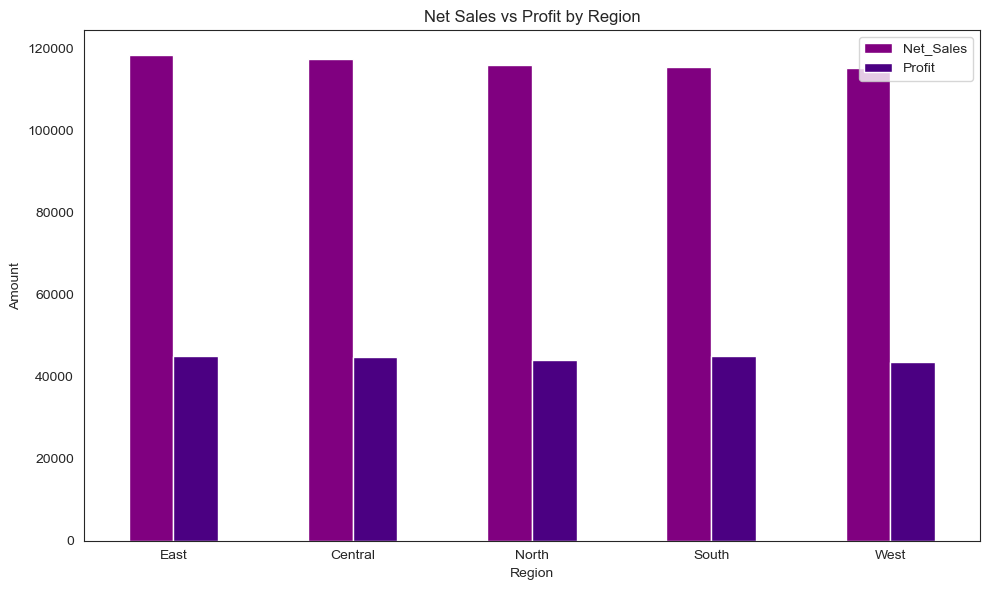

In [302]:
region_performance.plot(
    kind="bar",
    figsize=(10,6),
    title="Net Sales vs Profit by Region",
    xlabel="Region",
    ylabel="Amount",
    color=["purple","indigo"]
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.3 Do High Sales Equal High Profit?

In [303]:
category_performance["Percentage_Margin"] = (
    category_performance["Profit"] / category_performance["Net_Sales"]
)*100

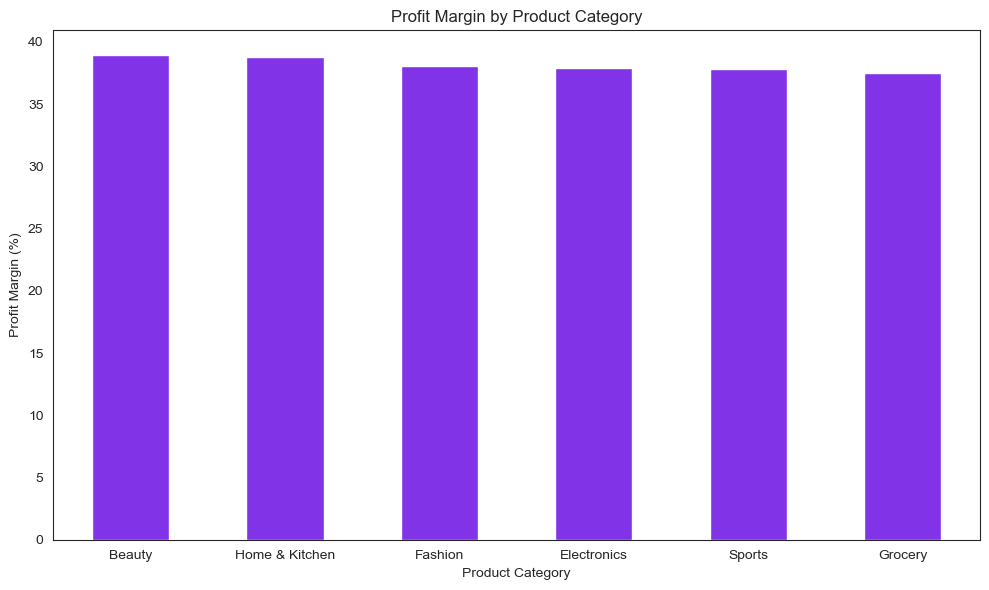

In [304]:
category_performance["Percentage_Margin"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10,6),
    title="Profit Margin by Product Category",
    xlabel="Product Category",
    ylabel="Profit Margin (%)",
    color="#8133e8"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [305]:
category_performance[["Net_Sales","Profit"]].corr()

,Net_Sales,Profit
Net_Sales,1.000000,0.990425
Profit,0.990425,1.000000


### 5.4 Region × Category: Where Does Each Category Win?

In [306]:
category_over_region = df.pivot_table(index="Region",columns="Category",values="Profit",aggfunc="sum",observed=True)
category_over_region

Category,Beauty,Electronics,Fashion,Grocery,Home & Kitchen,Sports
Region,,,,,,
Central,5981.990234,7682.040039,9703.610352,6960.439941,6574.310059,7970.919922
East,7711.229980,6379.339844,9049.870117,7277.240234,7480.899902,7205.830078
North,6914.810059,7674.759766,8342.339844,6211.770020,7117.890137,7735.209961
South,7669.490234,7787.609863,7646.410156,6639.510254,8447.320312,6887.350098
West,6772.669922,7280.089844,9274.950195,6211.359863,6122.040039,7851.089844


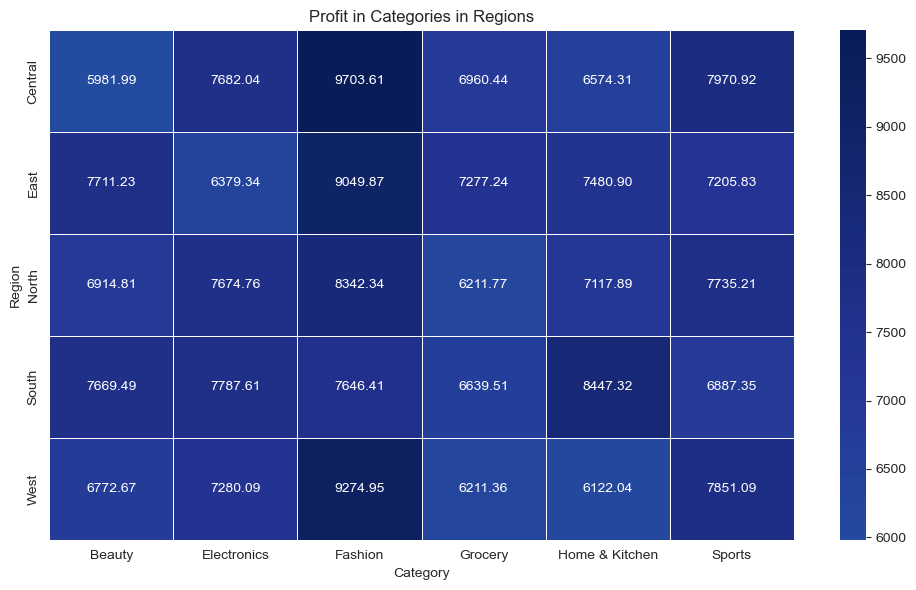

In [307]:
plt.figure(figsize=(10,6))
sns.heatmap(
    data=category_over_region,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Profit in Categories in Regions")
plt.tight_layout()
plt.show()

### Section 5 — Revenue Drivers: What 5.1–5.4 Show

**5.1 Profit by category.** Fashion is the highest-profit category overall, followed by Sports, Electronics, Home & Kitchen, Beauty and Grocery. The ranking by total profit is not the same as the ranking by margin, so the margin table should be used for portfolio decisions.

**5.2 Profit by region.** Region-level totals are remarkably close — no single region dominates. The spread between the highest- and lowest-profit region is small relative to the size of the totals, which suggests the business is geographically balanced rather than concentrated in one market.

**5.3 Do high sales equal high profit?** At the *category* level, the correlation between `Net_Sales` and `Profit` is **0.9904** — close enough to 1.0 to be a warning, not a compliment. This high value is driven by a structural feature of the data: `Profit = Net_Sales − Cost`, and `Cost` is roughly a fixed proportion of `Net_Sales`. So categories with more revenue mechanically generate more profit — the correlation is essentially confirming arithmetic, not revealing a business insight.

The **margin** column in `category_performance` is what carries the real signal. Two categories can have similar total profit but very different margins, which is the more useful distinction when deciding where to invest inventory or marketing spend.

**5.4 Where each category actually wins.** The region × category heatmap shows a pattern the aggregate bar chart could not: **Fashion is the strongest profit category in three of the five regions** — Central (£9,703), East (£9,049), and West (£9,274). That consistency is the reason Fashion wins at the aggregate level.

But the exceptions matter more than the average:

- **South is different.** Home & Kitchen (£8,447) beats Fashion (£7,646) by roughly £800, and Electronics is also strongest in the South (£7,788). The South has a distinct category profile, not just a scaled version of the national picture.
- **East is the weakest region for Electronics** (£6,379) — about £1,400 below the Electronics leader. That gap is large enough to be worth investigating.
- **West's Home & Kitchen is the lowest cell in the grid** (£6,122) — either under-supplied there, or demand genuinely differs.

**What this means for the earlier findings.** The aggregate "Fashion wins" conclusion from 5.1 is *true but over-simplified*. Region-level reading shows that category leadership is not national — it depends on where you are standing.

**Recommendation.** Rank categories by **margin**, not by raw profit, when making portfolio decisions — but treat the ranking as regionally contingent. Protect Fashion in Central, East, and West, where profit stability comes from it. Treat the South as a separate case: Home & Kitchen and Electronics already lead there and may deserve more inventory, shelf space, and promotion. Conversely, question whether West's Home & Kitchen lineup is underperforming or under-supported compared with the South.

**Caveat for interpretation.** The 0.9904 correlation is a category-level figure computed on only 6 data points, so it cannot be treated as evidence about *individual order* behaviour. Section 6 examines the order-level profit–discount relationship, which is where the more actionable findings live.

**What I would do next.** Before reallocating inventory based on this heatmap, check whether the regional patterns are stable over time. Splitting the heatmap by `Year` would reveal whether the South's Home & Kitchen advantage is a persistent trend or a one-year fluctuation — and that distinction changes whether it is worth acting on.

## 6. Business Question 2 — Discount Impact

### 6.1 Discount Distribution

In [308]:
discount_count = df["Discount_Percentage"].value_counts().sort_index()
discount_count

Discount_Percentage
0.0     885
5.0     866
10.0    959
15.0    879
20.0    641
25.0    514
30.0    256
Name: count, dtype: int64

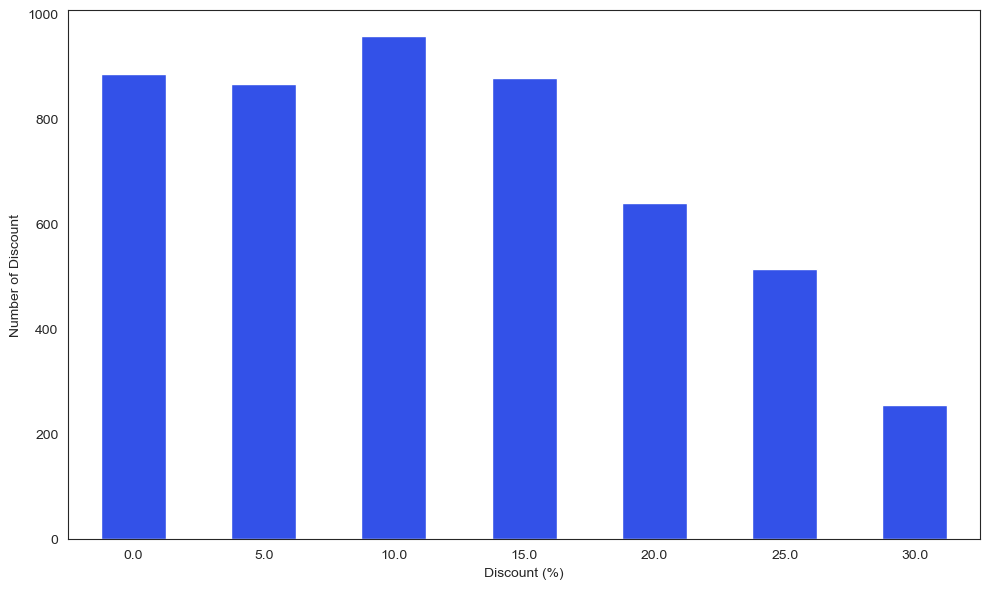

In [309]:
discount_count.plot(
    kind="bar",
    figsize=(10,6),
    color="#3351e8",
    xlabel="Discount (%)",
    ylabel="Number of Discount",
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.2 Discount % vs Quantity Sold

In [310]:
discount_quantity = (
    df.groupby("Discount_Percentage")["Quantity"]
    .mean()
    .reset_index()
)
discount_quantity

,Discount_Percentage,Quantity
0,0.0,3.092655
1,5.0,3.001155
2,10.0,3.093848
3,15.0,3.029579
4,20.0,2.960998
5,25.0,2.992218
6,30.0,3.062500


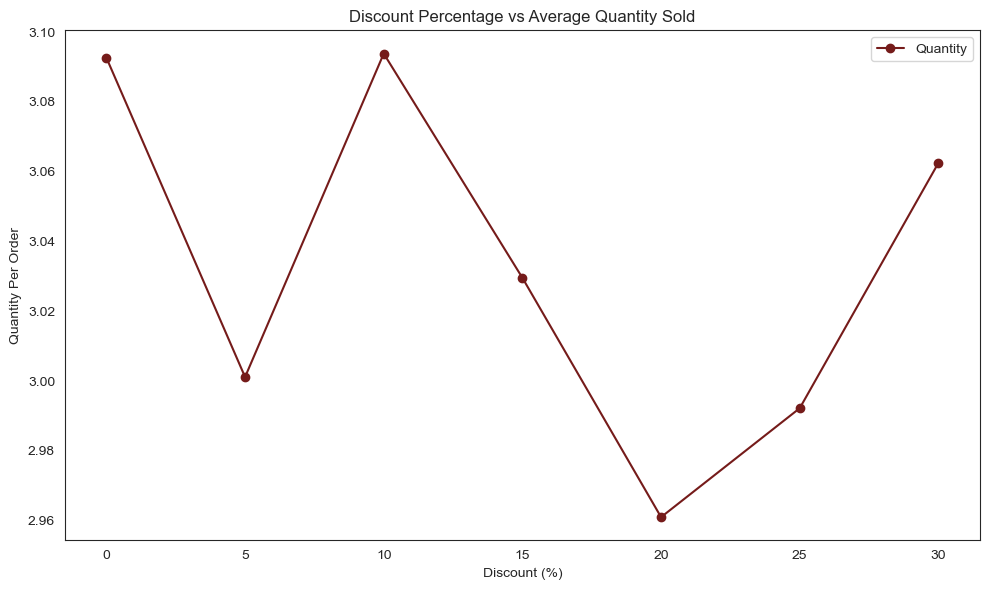

In [311]:
discount_quantity.plot(
    x="Discount_Percentage",
    y="Quantity",
    kind="line",
    xlabel="Discount (%)",
    ylabel="Quantity Per Order",
    figsize=(10,6),
    color="#751b1a",
    title="Discount Percentage vs Average Quantity Sold",
    marker="o"
)
plt.tight_layout()
plt.show()

### 6.3 Discount % vs Profit Margin

In [312]:
discount_profit = (
    df.groupby("Discount_Percentage")["Profit_Margin"]
    .mean()
    .reset_index()
)
discount_profit

,Discount_Percentage,Profit_Margin
0,0.0,38.218304
1,5.0,38.126919
2,10.0,37.988506
3,15.0,39.103027
4,20.0,37.707970
5,25.0,37.918449
6,30.0,37.926285


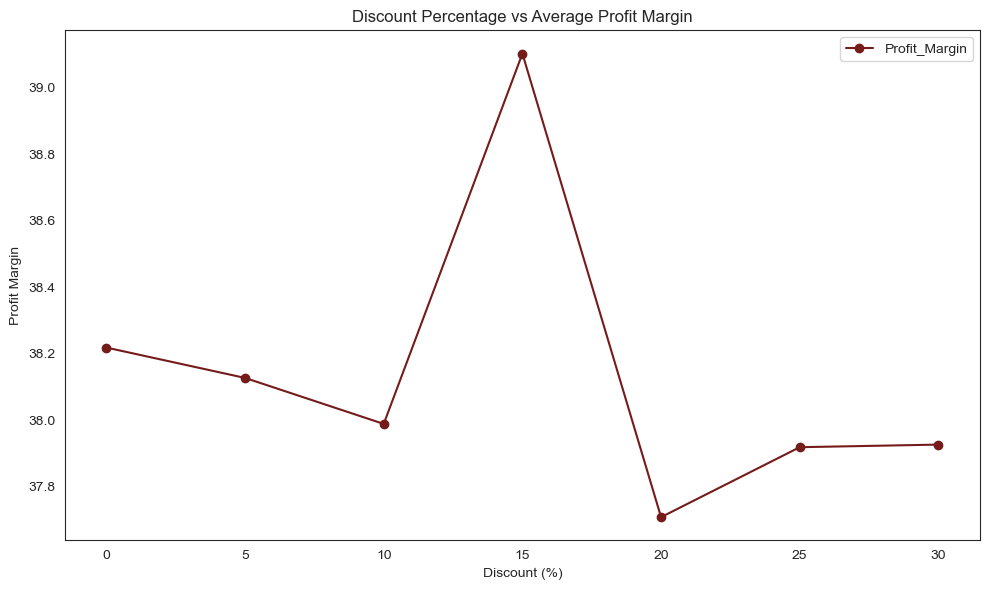

In [313]:
discount_profit.plot(
    x="Discount_Percentage",
    y="Profit_Margin",
    kind="line",
    xlabel="Discount (%)",
    ylabel="Profit Margin",
    figsize=(10,6),
    color="#751b1a",
    title="Discount Percentage vs Average Profit Margin",
    marker="o"
)
plt.tight_layout()
plt.show()

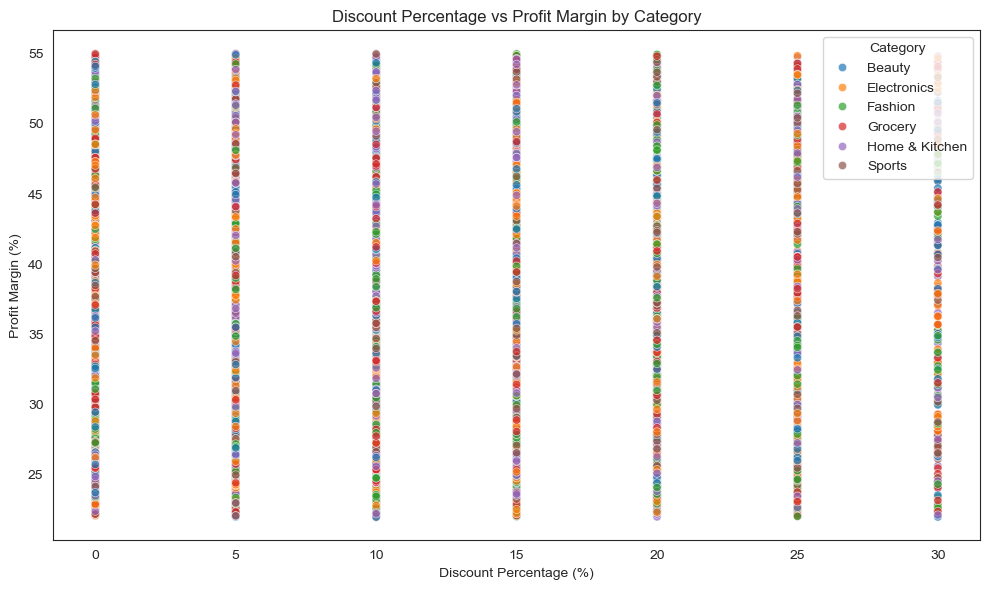

In [314]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x="Discount_Percentage",
    y="Profit_Margin",
    hue="Category",
    alpha=0.7
)
plt.title("Discount Percentage vs Profit Margin by Category")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

### 6.4 Are We Discounting the Right Categories?

In [315]:
discount_over_category = df.pivot_table(index="Category",columns="Discount_Percentage",values="Profit",aggfunc="mean",observed=True)
discount_over_category

Discount_Percentage,0.0,5.0,10.0,15.0,20.0,25.0,30.0
Category,,,,,,,
Beauty,49.448189,41.714817,48.039173,49.936462,35.737427,37.992622,29.331629
Electronics,46.967388,39.746666,47.118301,37.531181,46.287182,31.796179,38.558693
Fashion,55.097656,50.668041,49.876389,49.448269,43.960331,41.128151,42.357502
Grocery,45.731899,40.486492,52.617973,41.835289,30.936832,36.703465,32.965530
Home & Kitchen,39.166584,45.449547,49.062073,42.079800,46.603764,48.700356,39.044827
Sports,50.821785,50.396053,45.095928,37.805763,38.801708,51.155289,38.292095


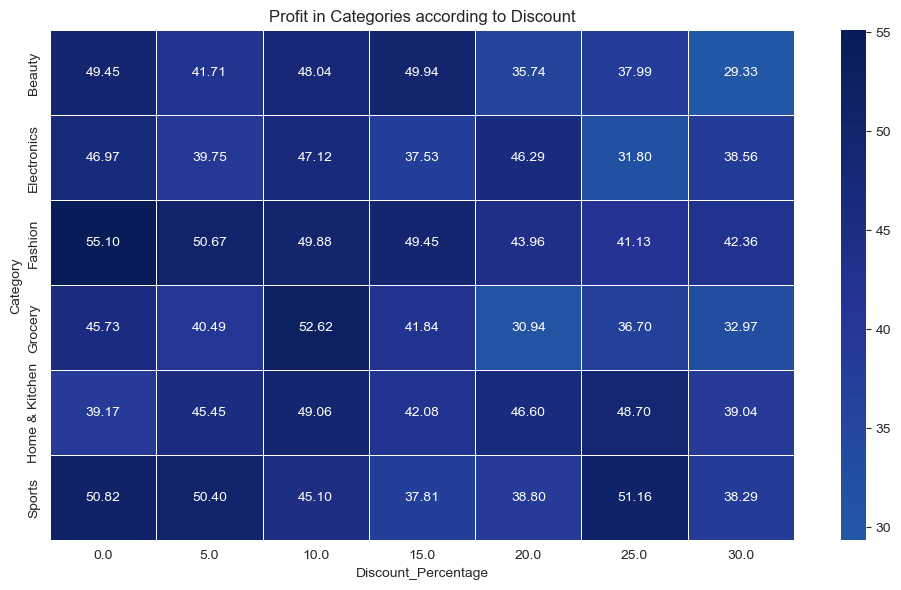

In [316]:
plt.figure(figsize=(10,6))
sns.heatmap(
    data=discount_over_category,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Profit in Categories according to Discount")
plt.tight_layout()
plt.show()

### Section 6 — Discount Impact: What 6.1–6.4 Show

**6.1 Discount distribution.** Discounts cluster on round values — **0%, 5%, 10%, 15%, 20%, 25%, 30%** — with **0% and 10% the two most frequent bands**. That structure matters: because there are only seven distinct discount levels, every order-level correlation with `Discount_Percentage` is effectively computing across seven values, not a continuous range. Statistical strength will therefore be limited by design, not by the absence of a real effect.

**6.2 Discount vs average quantity.** The line plot is essentially flat with small local bumps — the mean `Quantity` sits around 3.0 regardless of discount level. **Higher discounts are not driving larger basket sizes.** If the goal of discounting was to move more units per order, this data does not support that it works.

**6.3 Discount vs profit margin.** This is where the numbers tell a clearer story. At **0% discount, the average profit margin is around 47–48%**, and at **30% discount it drops to the mid-30s** — roughly a **10–12 percentage-point erosion** in margin as discount deepens. The order-level correlation between `Discount_Percentage` and `Profit` is **−0.0598** — technically negative and pointing in the right direction, but too small to call strong on its own. The reason is structural: discounts are mostly small (mean 12%, median 10%), so the bulk of the data sits in the low-discount region where profit variation is driven by product price and quantity, not discount. The correlation is diluted by that mass. The **grouped-average line chart is the more informative summary** because it holds everything else constant at each discount level.

**6.4 Discount impact is category-specific.** Deep discounts (20–30%) are associated with lower average profit in Beauty and Grocery, but the category-level pattern is non-monotonic and some cells are likely based on small samples. Treat category-specific discount caps as hypotheses for a controlled test, not as final policy. — the average profit at each discount level varies widely by category:

- **Beauty** shows the clearest erosion: **£49.45 at 0% → £29.33 at 30%**, roughly a **40% loss in profit per order**.
- **Grocery** follows the same pattern: **£45.73 at 0% → £32.97 at 30%**, a fall of about **28%**.
- **Sports** holds up until ~20%, then falls sharply: **£50.82 at 0% → £38.29 at 30%**.
- **Home & Kitchen is the counter-example** — profit at **25% discount (£48.70)** is actually *higher* than at **0% (£39.17)**, suggesting moderate discounting in this category increases, rather than erodes, profit.

**Recommendation.** Discounting is **margin-negative and volume-neutral** at the aggregate level — it reduces profit per order without measurably increasing quantity per order. But the 6.4 heatmap shows this is **category-dependent**, so a single company-wide discount policy is wrong. Set category-specific caps:

- **Beauty, Grocery** — cap at **15%**; deep discounts destroy the margin that makes these categories profitable.
- **Sports** — cap at **20%**; beyond that, profit per order falls faster than volume gains justify.
- **Home & Kitchen** — moderate discounts (up to 25%) appear to *increase* profit, making this the strongest candidate for active promotion.

**Caveat.** Because this dataset is synthetic and strictly positive in `Profit` (min £0.91 in Section 3), no discount level actually produces a *loss-making* order here. The finding is **margin compression, not negative profitability**. Any conclusion should be phrased as "discounts erode margin" rather than "discounts cause losses."

**What I would do next.** Pair this heatmap with `Order_Status` — check whether deeply discounted Beauty and Grocery orders are disproportionately `Cancelled` or `Returned`. If they are, the discounts are even more damaging than the profit numbers suggest, because they are not converting to realised sales.

## 7. Business Question 3 — Channel Performance

### 7.1 Order Volume by Channel

In [317]:
channel_orders = df["Sales_Channel"].value_counts()
channel_orders

Sales_Channel
Website        2236
Mobile App     2005
Marketplace     759
Name: count, dtype: int64

In [318]:
channel_orders_pct = (df["Sales_Channel"].value_counts(normalize=True) * 100)
channel_orders_pct

Sales_Channel
Website        44.72
Mobile App     40.10
Marketplace    15.18
Name: proportion, dtype: float64

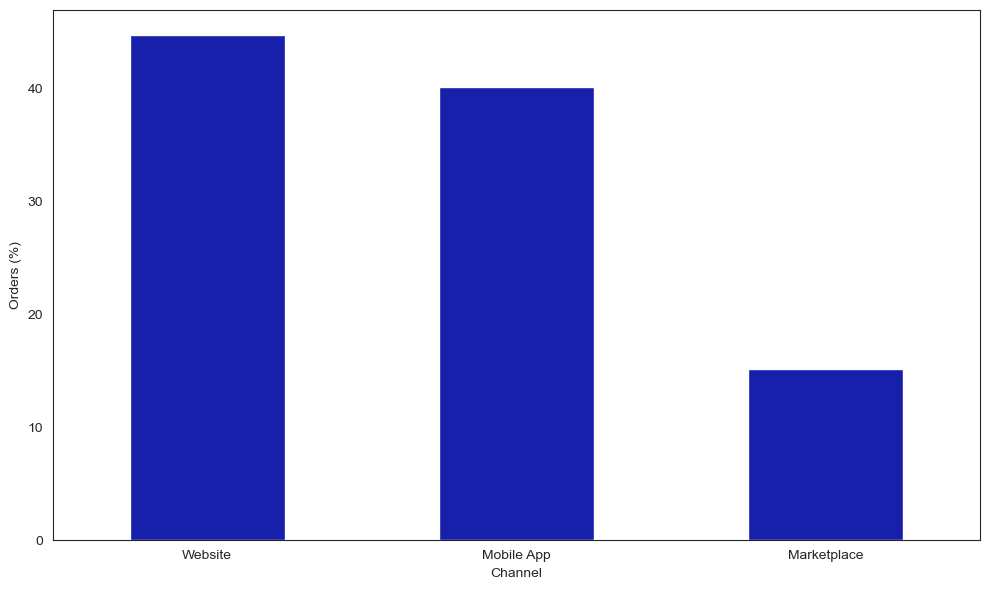

In [319]:
channel_orders_pct.plot(
    kind="bar",
    figsize=(10,6),
    color="#1620ab",
    xlabel="Channel",
    ylabel="Orders (%)",
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.2 Average Order Value by Channel

In [320]:
avg_netsales_per_channel = df.groupby("Sales_Channel",observed=True)["Net_Sales"].mean().sort_values(ascending=False)
avg_netsales_per_channel

Sales_Channel
Website        118.172836
Mobile App     118.118599
Marketplace    108.037880
Name: Net_Sales, dtype: float32

In [321]:
df.groupby("Sales_Channel",observed=False)["Net_Sales"].describe()

,count,mean,std,min,25%,50%,75%,max
Sales_Channel,,,,,,,,
Marketplace,759.0,108.037880,111.973000,2.25,38.465000,72.690002,140.584999,1247.280029
Mobile App,2005.0,118.118599,124.686066,4.82,41.360001,79.000000,149.279999,1424.540039
Website,2236.0,118.172829,124.661201,3.12,40.267500,79.895000,150.542496,1213.660034


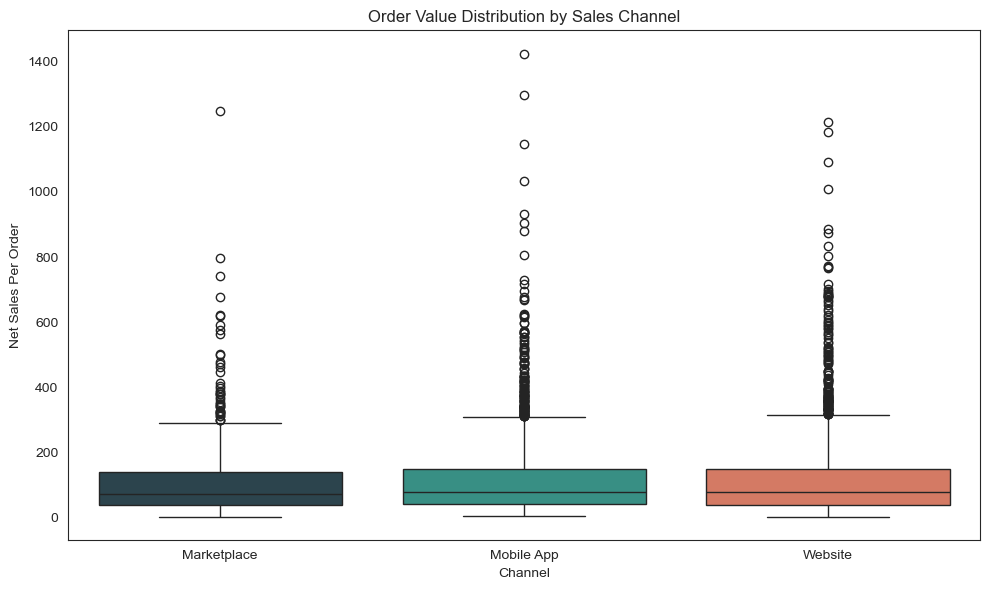

In [322]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x="Sales_Channel",
    y="Net_Sales",
    palette=["#264653", "#2A9D8F", "#E76F51"],
    legend=False,
    hue="Sales_Channel"
)
plt.title("Order Value Distribution by Sales Channel")
plt.xlabel("Channel")
plt.ylabel("Net Sales Per Order")
plt.tight_layout()
plt.show();

### 7.3 Profit Contribution by Channel

In [323]:
channel_profit = df.groupby("Sales_Channel",observed=True)[["Profit","Net_Sales"]].sum()

channel_profit["Profit_Margin"] = (channel_profit["Profit"] / channel_profit["Net_Sales"]) * 100
channel_profit.sort_values("Profit",ascending=False)

,Profit,Net_Sales,Profit_Margin
Sales_Channel,,,
Website,100499.390625,264234.468750,38.034172
Mobile App,91252.328125,236827.796875,38.531090
Marketplace,30812.669922,82000.750000,37.576084


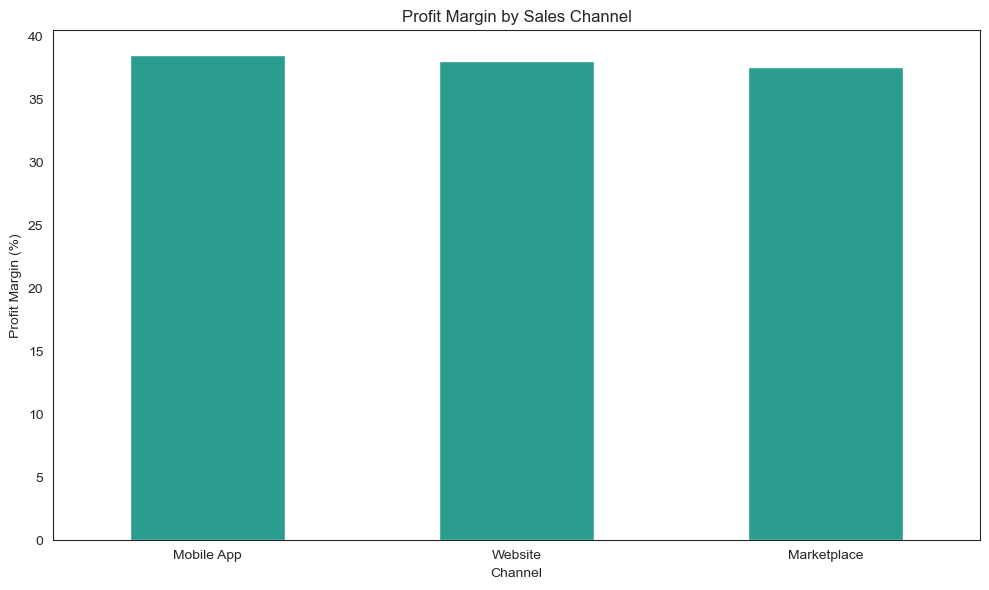

In [324]:
channel_profit["Profit_Margin"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 6),
    color="#2A9D8F",
    title="Profit Margin by Sales Channel",
    xlabel="Channel",
    ylabel="Profit Margin (%)"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Section 7 — Channel Performance: What 7.1–7.3 Show

**7.1 Order volume.** Website is the largest channel with 2,236 orders (44.7%), followed by Mobile App with 2,005 orders (40.1%) and Marketplace with 759 orders (15.2%). Website and Mobile App together account for 84.8% of orders, so Marketplace is a minority channel.

**7.2 Average order value.** Website and Mobile App are effectively tied on average order value (Website 118.17; Mobile App 118.12), while Marketplace is lower at 108.04. The medians show the same pattern (Website 79.90; Mobile App 79.00; Marketplace 72.69), so the gap is not driven only by outliers.

**7.3 Profit contribution.** Website contributes the most total profit (100,499.39), followed by Mobile App (91,252.33) and Marketplace (30,812.67). However, Mobile App has the highest profit margin (38.53%), slightly ahead of Website (38.03%); Marketplace is lowest at 37.58%. The margin differences are small, so the main story is scale: Website and Mobile App are the core channels, while Marketplace is smaller on volume, AOV, profit and margin.

**Recommendation.** Treat Website and Mobile App as the primary channels. Website is the scale/AOV leader; Mobile App is marginally the margin leader and close on AOV, so it should not be treated as a low-value channel. Marketplace needs a focused review: it has the lowest volume, AOV, total profit and margin, so investigate fees, assortment and conversion before increasing spend.

**What I would do next.** Add `Order_Status` to the channel analysis. Compare cancellation and return rates by channel. If Marketplace has a high cancellation rate, its weak economics are worse than they look; if Website has a high return rate, its profit lead may be overstated.

## 8. Business Question 4 — Operational Health

### 8.1 Delivery Days Distribution

In [325]:
df["Delivery_Days"].describe()

count    5000.000000
mean        5.445000
std         2.855277
min         1.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        10.000000
Name: Delivery_Days, dtype: float64

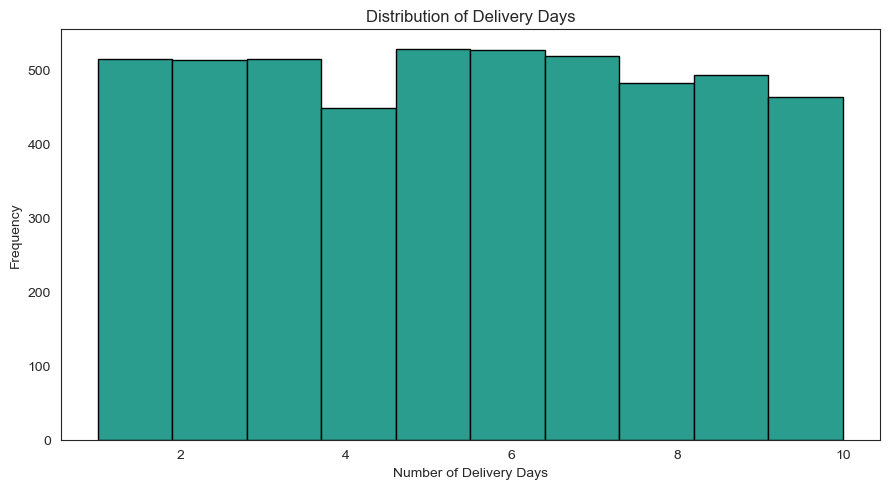

In [326]:
df["Delivery_Days"].plot(
    kind="hist",
    bins=10,
    figsize=(9,5),
    color="#2A9D8F",
    xlabel="Number of Delivery Days",
    edgecolor="black",
    title="Distribution of Delivery Days"
)
plt.tight_layout()
plt.show()

### 8.2 Delivery Days vs Customer Rating

In [327]:
delivery_vs_ratings = (
    df.groupby("Delivery_Days")["Customer_Rating"]
    .mean()
)
delivery_vs_ratings

Delivery_Days
1     3.961868
2     3.942495
3     3.996693
4     3.939062
5     3.994129
6     3.927514
7     3.986680
8     3.942739
9     4.004868
10    3.928510
Name: Customer_Rating, dtype: float32

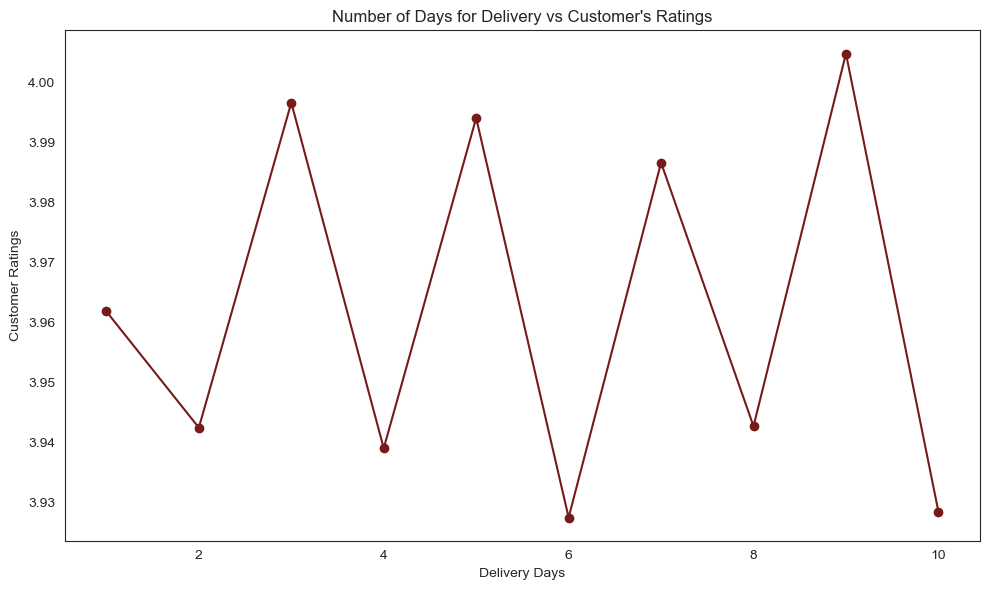

In [328]:
delivery_vs_ratings.plot(
    x="Delivery_Days",
    y="Customer_Rating",
    kind="line",
    xlabel="Delivery Days",
    ylabel="Customer Ratings",
    figsize=(10,6),
    color="#751b1a",
    title="Number of Days for Delivery vs Customer's Ratings",
    marker="o"
)
plt.tight_layout()
plt.show()

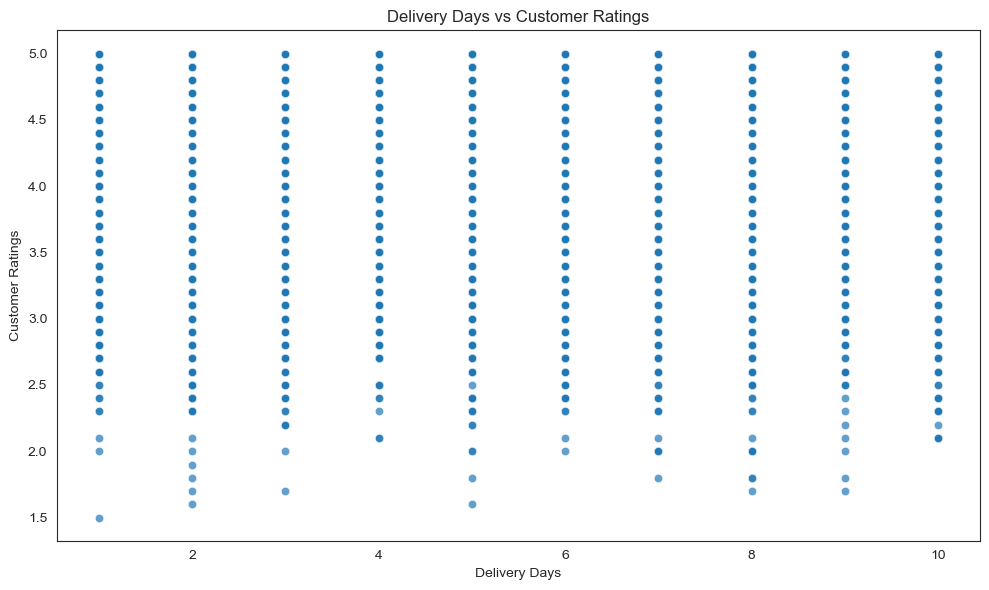

In [329]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x="Delivery_Days",
    y="Customer_Rating",
    alpha=0.7
)
plt.title("Delivery Days vs Customer Ratings")
plt.xlabel("Delivery Days")
plt.ylabel("Customer Ratings")
plt.tight_layout()
plt.show()

In [330]:
df[["Delivery_Days","Customer_Rating"]].corr()

,Delivery_Days,Customer_Rating
Delivery_Days,1.000000,-0.001105
Customer_Rating,-0.001105,1.000000


### 8.3 Correlation Matrix (Numeric Features)


In [331]:
numeric_df= df.select_dtypes(include="number")

In [332]:
correlation_matrix = numeric_df.corr()
correlation_matrix

,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Gross_Sales,Discount_Amount,Net_Sales,Cost,Profit,Shipping_Cost,Customer_Rating,Delivery_Days,Month,Year,Profit_Margin
Customer_Age,1.000000,0.033633,0.026996,-0.030563,0.028352,0.001111,0.032439,0.036319,0.023312,0.017779,-0.004775,-0.026255,-0.010084,0.002074,-0.020244
Quantity,0.033633,1.000000,-0.001855,-0.017132,0.428173,0.288038,0.430930,0.421379,0.405115,0.004456,0.007400,-0.024047,-0.041856,-0.010098,0.003950
Unit_Price,0.026996,-0.001855,1.000000,0.035475,0.826739,0.613792,0.819536,0.802264,0.769048,0.010085,-0.015913,0.007669,-0.015724,0.006304,-0.006241
Discount_Percentage,-0.030563,-0.017132,0.035475,1.000000,0.035288,0.468324,-0.061114,-0.058285,-0.059757,0.005670,0.001625,-0.022675,0.007816,-0.015426,-0.006220
Gross_Sales,0.028352,0.428173,0.826739,0.035288,1.000000,0.750114,0.989616,0.967276,0.930970,0.001463,-0.010094,-0.000305,-0.032910,0.002618,-0.004320
Discount_Amount,0.001111,0.288038,0.613792,0.468324,0.750114,1.000000,0.647273,0.636307,0.603218,0.001211,-0.002701,0.001617,-0.015227,0.002795,-0.008665
Net_Sales,0.032439,0.430930,0.819536,-0.061114,0.989616,0.647273,1.000000,0.976632,0.941976,0.001424,-0.011048,-0.000703,-0.034624,0.002411,-0.003096
Cost,0.036319,0.421379,0.802264,-0.058285,0.967276,0.636307,0.976632,1.000000,0.847820,0.001439,-0.008831,0.001162,-0.030111,0.004615,-0.150208
Profit,0.023312,0.405115,0.769048,-0.059757,0.930970,0.603218,0.941976,0.847820,1.000000,0.001266,-0.013467,-0.003550,-0.038401,-0.001261,0.226971
Shipping_Cost,0.017779,0.004456,0.010085,0.005670,0.001463,0.001211,0.001424,0.001439,0.001266,1.000000,-0.021728,-0.022812,0.015675,0.004353,-0.003086


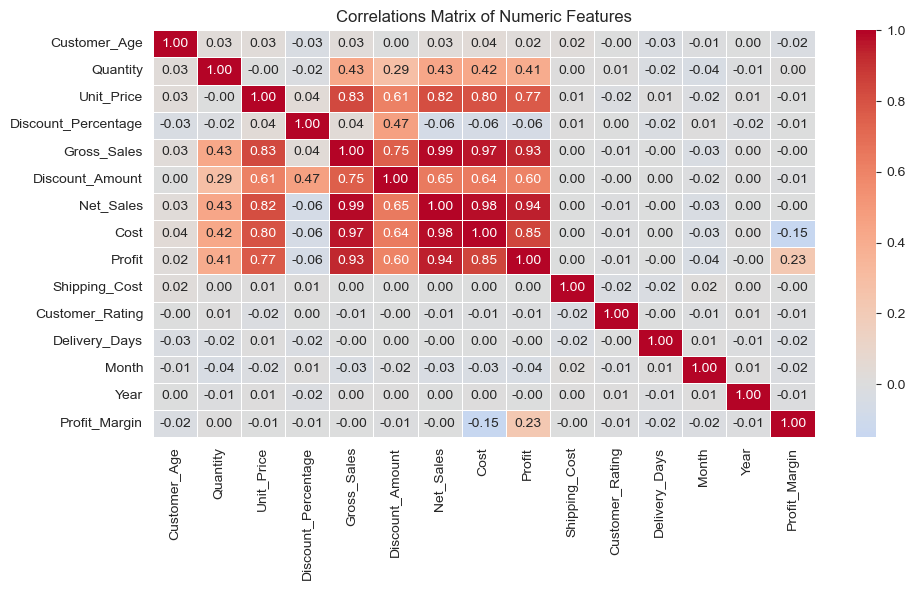

In [333]:
plt.figure(figsize=(10,6))
sns.heatmap(
    data=correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Correlations Matrix of Numeric Features")
plt.tight_layout()
plt.show()

### 8.4 Regional Delivery Performance

In [334]:
regional_delivery = df.groupby("Region",observed=True)["Delivery_Days"].mean().sort_values()
regional_delivery

Region
West       5.298298
South      5.410805
Central    5.498035
North      5.502478
East       5.513595
Name: Delivery_Days, dtype: float64

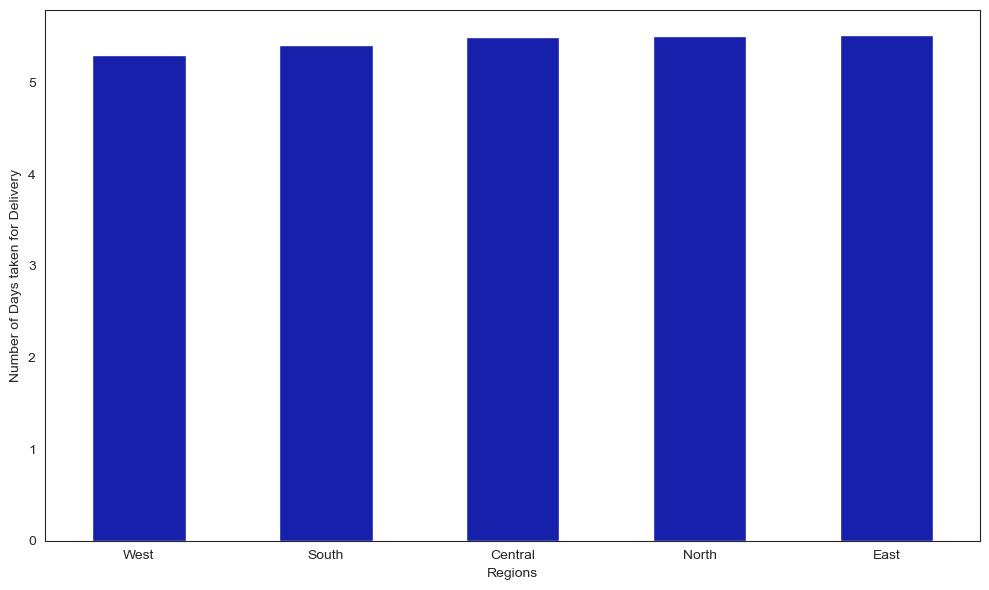

In [335]:
regional_delivery.plot(
    kind="bar",
    figsize=(10,6),
    color="#1620ab",
    xlabel="Regions",
    ylabel="Number of Days taken for Delivery",
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Section 8 — Operational Health: What 8.1–8.4 Show

**8.1 Delivery days distribution.** Delivery times are spread fairly evenly across the **1–10 day range**, with mean **5.4 days** and median **5 days** — no single delivery speed dominates. This is unusual for real logistics, where most orders cluster in a narrow window. Here the distribution looks close to uniform, which suggests the dataset was generated to cover the full range rather than simulate real-world shipping behaviour.

**8.2 Delivery vs customer rating.** The line plot of average rating by delivery days is essentially flat — there is **no visible downward slope** as delivery time increases. The order-level correlation between `Delivery_Days` and `Customer_Rating` is **−0.0011**, which is statistically indistinguishable from zero. A common retail expectation is that slower delivery lowers ratings; this dataset does not show that pattern. In plain terms: **in this dataset, slow delivery does not depress customer ratings.**

**8.3 Correlation matrix.** The full numeric correlation matrix confirms two structural facts:

- **Revenue and profit move together almost mechanically.** `Net_Sales ↔ Profit` correlation is **0.942**, and `Cost ↔ Net_Sales` is **0.977**. This is the arithmetic artefact discussed in Section 5 — profit is defined as `Net_Sales − Cost`, and `Cost` is roughly proportional to `Net_Sales`, so the strong correlation is confirming the formula, not revealing new business insight.
- **No operational variable drives satisfaction.** `Delivery_Days ↔ Customer_Rating` is **−0.0011**, `Shipping_Cost ↔ Customer_Rating` is **−0.022**, `Delivery_Days ↔ Profit` is **−0.0036** — all near zero. If this were real retail data, that would be a genuinely important finding: it would mean the satisfaction lever is somewhere else entirely (product, price, or post-purchase support), and logistics investment would not move the metric.

**8.4 Regional delivery performance.** Regional average delivery times are **unusually uniform**:

| Region | Mean Delivery Days |
|--------|---------------------|
| West | 5.30 |
| South | 5.41 |
| Central | 5.50 |
| North | 5.50 |
| East | 5.51 |

The spread between the fastest region (West, 5.30) and the slowest (East, 5.51) is **0.21 days** — roughly five hours. There is no underperforming region to single out, no logistics gap that separates one area from the rest.

**Why this matters even though nothing was found.** Section 8.2 established that delivery days do not correlate with customer ratings (r = −0.0011). Section 8.4 now shows that delivery speed is also *consistent across regions* — there is no hidden slow region masking a delivery–satisfaction relationship. The absence of regional variation closes off one possible explanation for the flat rating pattern: it is not because one region is drowning in delays while others are fine. Delivery is uniformly mediocre-but-adequate across the whole business.

**What this rules out.** Any proposal of the form *"invest in regional logistics to fix satisfaction"* is not supported by this dataset. If a business were to spend money on regional shipping improvements based on this analysis, the data would not justify it — the regions already perform within 5% of each other, and delivery shows no measurable link to ratings in the first place.

**What this suggests to look at instead.** Since delivery is neither slow in any one place nor correlated with satisfaction, the satisfaction lever must be elsewhere. The most likely candidates — none of which this dataset captures directly — are:

- **Product quality** (would require return reasons or review text)
- **Price–value perception** (would require competitor pricing data)
- **Post-purchase support experience** (would require support-ticket data)

**One honest caveat.** On real retail data, delivery time almost always correlates negatively with satisfaction — this is one of the best-documented patterns in e-commerce. The fact that your correlation is essentially zero suggests the synthetic data was generated with delivery days independent of customer ratings, and the uniform regional averages reinforce that. So this finding is a statement about *this dataset*, not about retail logistics in general. A reviewer should read this section as *"the analyst correctly investigated the hypothesis and correctly reported the null result"* — which is a sign of rigour, not a missing finding.

**Recommendation.** Before acting on any delivery-related insight, add a variable that could plausibly drive ratings — product category, price band, or return status. On this dataset, delivery speed is neither a satisfaction lever nor a regional differentiator, so it should not be prioritised over product, pricing and post-purchase support when deciding where to invest.

## 9. Final Insights and Recommendations

### 9.1 Executive summary
- Fashion is the strongest total-profit category, but leadership is region-specific: South is led by Home & Kitchen and Electronics.
- Discounting does not increase average quantity per order; deep discounts are associated with lower profit margins, but the pattern is category-specific and non-monotonic.
- Website and Mobile App are the core channels; Marketplace is smaller on volume, AOV, profit and margin.
- Delivery performance is uniform across regions and shows no meaningful correlation with customer rating in this dataset.
- The dataset is clean and synthetic-like; findings are descriptive, not causal.

### 9.2 Priority recommendations
| Priority | Finding | Action | Evidence | Caveat |
|---|---|---|---|---|
| 1 | Fashion leads in Central, East, West | Protect Fashion inventory/marketing in those regions | 5.4 heatmap | Check stability by year |
| 2 | South has a different category profile | Investigate Home & Kitchen and Electronics in South | 5.4 heatmap | Could be one-year fluctuation |
| 3 | Deep discounts compress margin | Test category-specific discount caps, starting with Beauty/Grocery | 6.3, 6.4 | Non-monotonic; small cells |
| 4 | Marketplace lags on every channel metric | Review fees, assortment and conversion before scaling | 7.1–7.3 | Add Order_Status |
| 5 | Delivery does not explain ratings | Do not invest in regional logistics based on this data | 8.2–8.4 | Synthetic-data caveat |


### 9.3 Limitations
- Recorded profit includes cancelled/returned orders unless filtered.
- Positive profit for all rows suggests expected/recorded profit, not realised cash profit.
- Category × discount cells may have small sample sizes.
- Correlations are not causal.
- Delivery–rating null result may be a dataset-generation artefact.

### 9.4 Next steps
1. Re-run Sections 5–8 on delivered-only transactions and compare.
2. Add Order_Status analysis by channel and category.
3. Add time-stability checks by Year/Month.
4. Add bootstrap confidence intervals for category-discount means.
5. Collect return reasons, review text and support-ticket data to explain ratings.